In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
file_path = "/content/LC_loans_granting_model_dataset.csv"

df = pd.read_csv(file_path)

# Basic inspection
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()


Dataset shape: (291202, 15)

Column names:
['id', 'issue_d', 'revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'emp_length', 'purpose', 'home_ownership_n', 'addr_state', 'zip_code', 'Default', 'title', 'desc']


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0.0,Debt consolidation,NaN
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0.0,Business,NaN
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0.0,NaN,NaN
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0.0,Major purchase,NaN
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0.0,Debt consolidation,NaN


In [2]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [3]:

default_counts = df["Default"].value_counts().sort_index()

default_percentages = (
    df["Default"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Default counts:")
print(default_counts)

print("\nDefault percentages:")
print(default_percentages.round(2))


Default counts:
Default
0.0    232464
1.0     58737
Name: count, dtype: int64

Default percentages:
Default
0.0    79.83
1.0    20.17
Name: proportion, dtype: float64


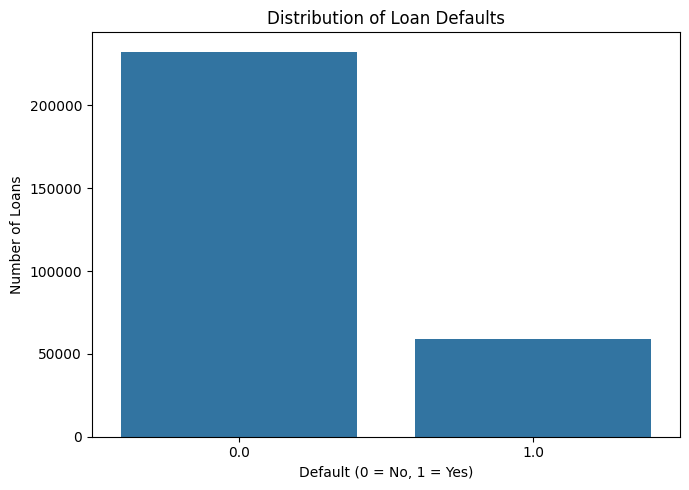

In [4]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Default")

plt.title("Distribution of Loan Defaults")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Number of Loans")

plt.tight_layout()
plt.show()


In [5]:

df["fico_band"] = pd.cut(
    df["fico_n"],
    bins=[0, 580, 670, 740, 800, 900],
    labels=[
        "Poor",
        "Fair",
        "Good",
        "Very Good",
        "Excellent"
    ]
)

fico_default = (
    df.groupby("fico_band", observed=False)["Default"]
    .agg(["mean", "count"])
    .reset_index()
)

fico_default["default_rate_pct"] = fico_default["mean"] * 100

print(fico_default)


   fico_band      mean   count  default_rate_pct
0       Poor       NaN       0               NaN
1       Fair  0.261474   56128         26.147377
2       Good  0.200376  208189         20.037562
3  Very Good  0.091507   24042          9.150653
4  Excellent  0.051020    2842          5.102041


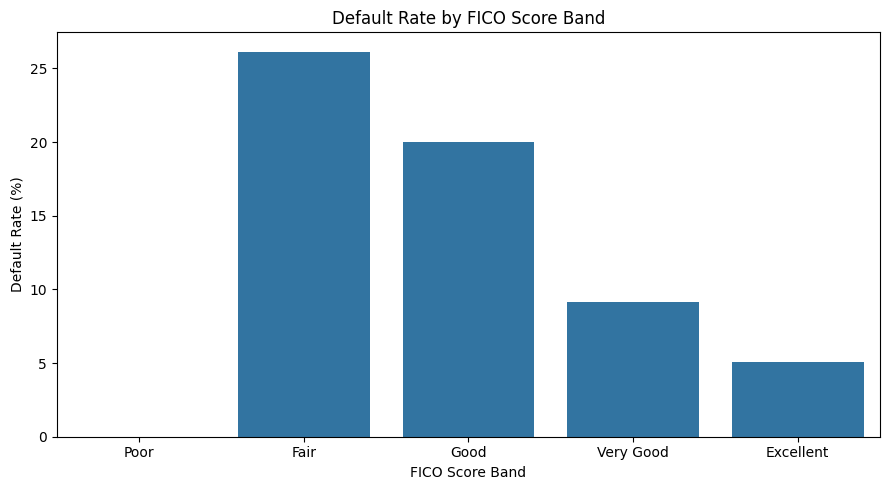

In [6]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=fico_default,
    x="fico_band",
    y="default_rate_pct"
)

plt.title("Default Rate by FICO Score Band")
plt.xlabel("FICO Score Band")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()


  dti_band  default_rate_pct
0     0–10         14.227126
1    10–20         17.584639
2    20–30         22.955840
3    30–40         29.802658
4      40+         24.193548


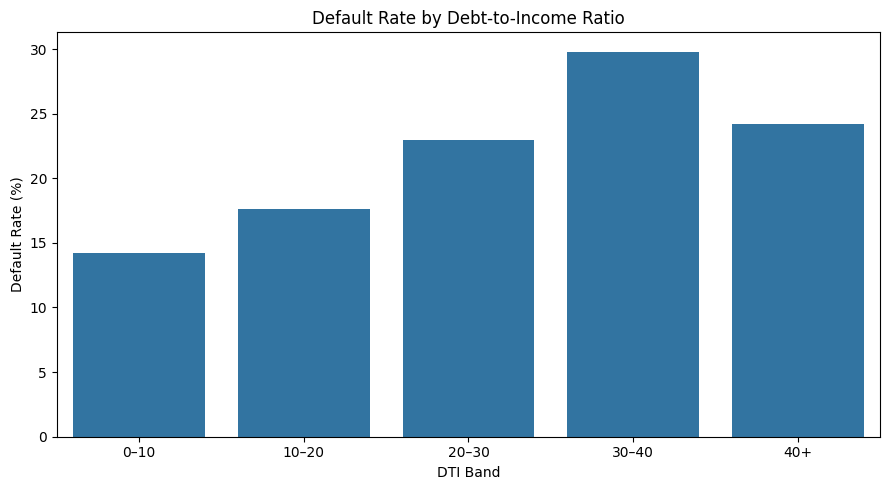

In [7]:

dti_data = df[df["dti_n"].between(0, 100)].copy()

dti_data["dti_band"] = pd.cut(
    dti_data["dti_n"],
    bins=[-0.01, 10, 20, 30, 40, 100],
    labels=[
        "0–10",
        "10–20",
        "20–30",
        "30–40",
        "40+"
    ]
)

dti_default = (
    dti_data.groupby("dti_band", observed=False)["Default"]
    .mean()
    .mul(100)
    .reset_index(name="default_rate_pct")
)

print(dti_default)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=dti_default,
    x="dti_band",
    y="default_rate_pct"
)

plt.title("Default Rate by Debt-to-Income Ratio")
plt.xlabel("DTI Band")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()


  loan_band  default_rate_pct
0  Up to 5k         15.400693
1    5k–10k         16.488906
2   10k–15k         21.876126
3   15k–25k         23.597895
4   25k–40k         22.840113


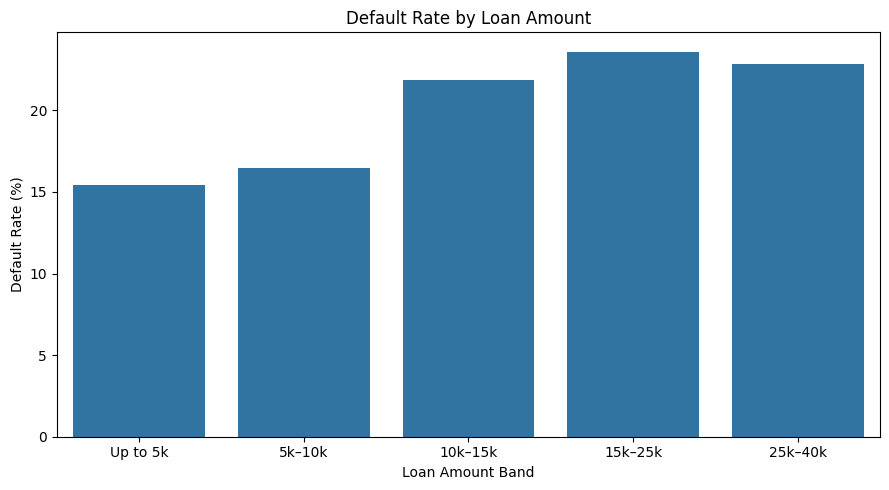

In [8]:

df["loan_band"] = pd.cut(
    df["loan_amnt"],
    bins=[0, 5000, 10000, 15000, 25000, 40000],
    labels=[
        "Up to 5k",
        "5k–10k",
        "10k–15k",
        "15k–25k",
        "25k–40k"
    ],
    include_lowest=True
)

loan_default = (
    df.groupby("loan_band", observed=False)["Default"]
    .mean()
    .mul(100)
    .reset_index(name="default_rate_pct")
)

print(loan_default)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=loan_default,
    x="loan_band",
    y="default_rate_pct"
)

plt.title("Default Rate by Loan Amount")
plt.xlabel("Loan Amount Band")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()


               purpose   count  default_rate_pct
11      small_business    2297             28.47
10    renewable_energy     166             25.30
5                house    1025             24.88
8               moving    1857             23.10
2   debt_consolidation  169921             21.70
9                other   14142             20.90
7              medical    2974             20.78
6       major_purchase    5415             19.21
12            vacation    1767             18.34
4     home_improvement   18394             17.97
1          credit_card   70704             16.75
0                  car    2535             15.46
3          educational       1              0.00
13             wedding       3              0.00


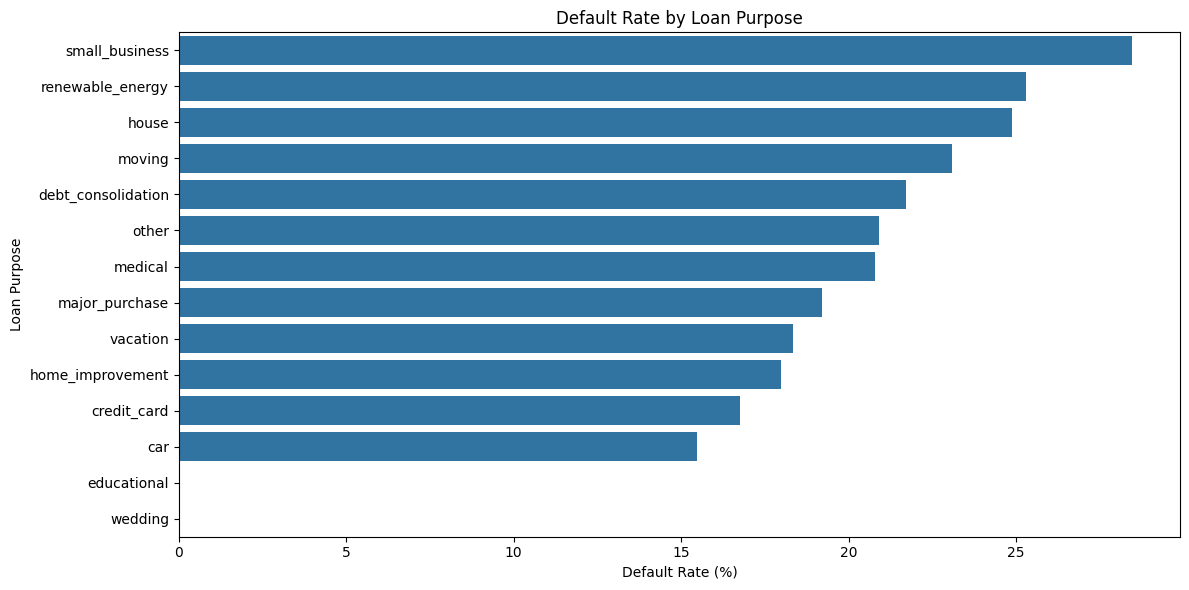

In [9]:

purpose_default = (
    df.groupby("purpose", observed=True)["Default"]
    .agg(["mean", "count"])
    .reset_index()
)

purpose_default["default_rate_pct"] = purpose_default["mean"] * 100

purpose_default = purpose_default.sort_values(
    "default_rate_pct", ascending=False
)

print(purpose_default[["purpose", "count", "default_rate_pct"]].round(2))

plt.figure(figsize=(12, 6))
sns.barplot(
    data=purpose_default,
    x="default_rate_pct",
    y="purpose"
)
plt.title("Default Rate by Loan Purpose")
plt.xlabel("Default Rate (%)")
plt.ylabel("Loan Purpose")
plt.tight_layout()
plt.show()


   emp_length  count  default_rate_pct
11         NI  17208             24.84
0      1 year  19446             20.80
8     8 years  14999             20.77
10   < 1 year  24041             20.46
9     9 years  11535             20.34
5     5 years  17481             20.27
4     4 years  17116             20.19
3     3 years  23259             20.08
7     7 years  12210             19.92
6     6 years  11424             19.87
2     2 years  26107             19.81
1   10+ years  96375             19.19


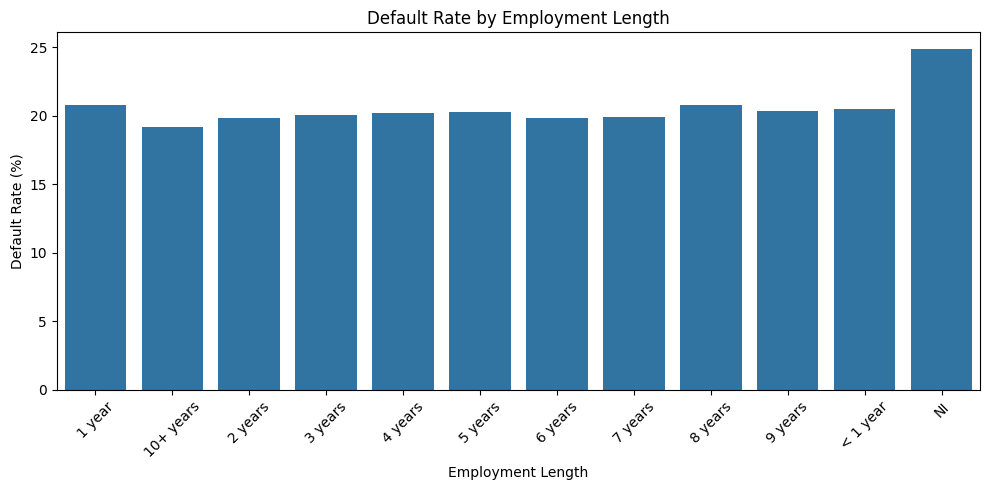

In [10]:

emp_default = (
    df.groupby("emp_length", observed=True)["Default"]
    .agg(["mean", "count"])
    .reset_index()
)

emp_default["default_rate_pct"] = emp_default["mean"] * 100

print(emp_default[["emp_length", "count", "default_rate_pct"]]
      .sort_values("default_rate_pct", ascending=False)
      .round(2))

plt.figure(figsize=(10, 5))
sns.barplot(
    data=emp_default,
    x="emp_length",
    y="default_rate_pct"
)
plt.title("Default Rate by Employment Length")
plt.xlabel("Employment Length")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [11]:
home_default = (
    df.groupby("home_ownership_n", observed=True)["Default"]
    .mean()
)

  home_ownership_n   count  default_rate_pct
0         MORTGAGE  141691             17.49
1            OTHER       2              0.00
2              OWN   32203             20.60
3             RENT  117305             23.29


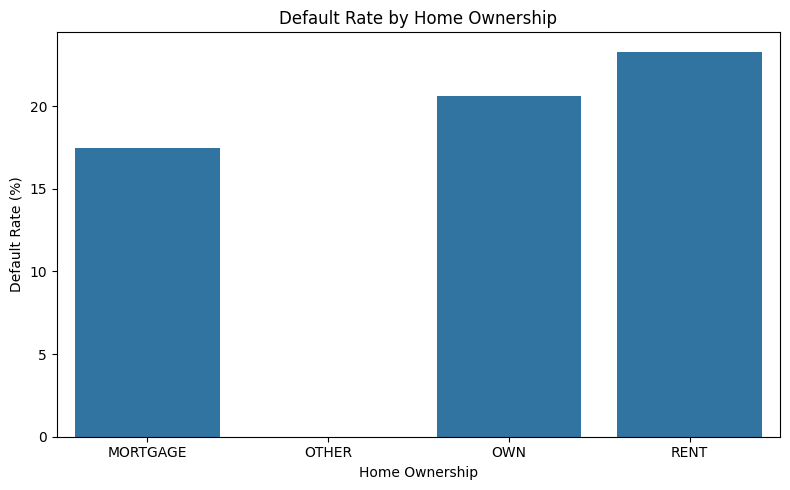

In [12]:

home_default = (
    df.groupby("home_ownership_n", observed=True)["Default"]
    .agg(["mean", "count"])
    .reset_index()
)

home_default["default_rate_pct"] = home_default["mean"] * 100

print(home_default[["home_ownership_n", "count", "default_rate_pct"]].round(2))

plt.figure(figsize=(8, 5))
sns.barplot(
    data=home_default,
    x="home_ownership_n",
    y="default_rate_pct"
)
plt.title("Default Rate by Home Ownership")
plt.xlabel("Home Ownership")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()


   issue_year   count  default_rate_pct
0        2015  291201             20.17


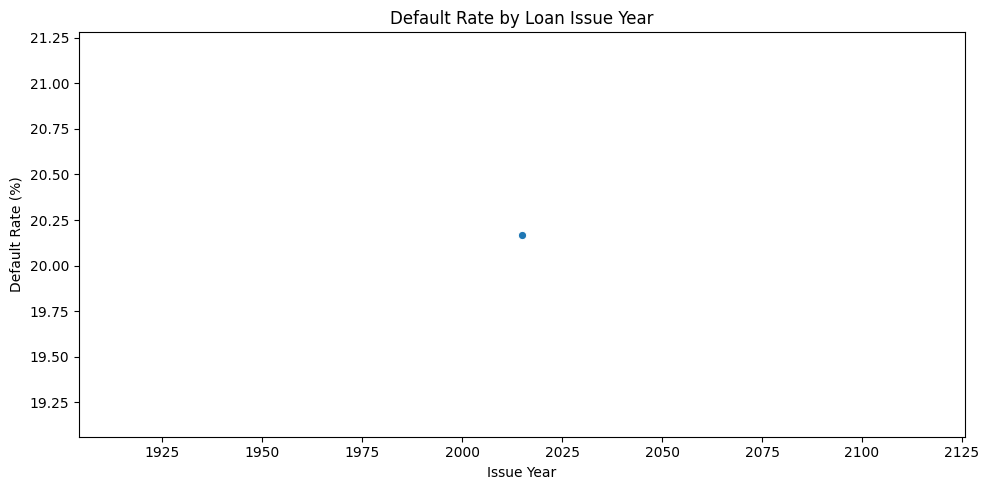

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ex tra ct issue_year from the issue_d colu mn (e.g., 'Dec-2015')
df['issue_year'] = pd.to_datetime(df['issue_d'], format='%b-%Y').dt.year

yearly_default = (
    df.groupby("issue_year", observed=True)["Default"]
    .agg(["mean", "count"])
    .reset_index()
)

yearly_default["default_rate_pct"] = yearly_default["mean"] * 100

print(yearly_default[["issue_year", "count", "default_rate_pct"]].round(2))

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=yearly_default,
    x="issue_year",
    y="default_rate_pct",
    marker="o"
)
plt.title("Default Rate by Loan Issue Year")
plt.xlabel("Issue Year")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()

In [14]:

print("CREDIT RISK EDA SUMMARY")
print("=" * 40)

print("\nHighest default rate by loan purpose:")
print(
    purpose_default.loc[
        purpose_default["default_rate_pct"].idxmax(),
        ["purpose", "count", "default_rate_pct"]
    ]
)

print("\nHighest default rate by home ownership:")
print(
    home_default.loc[
        home_default["default_rate_pct"].idxmax(),
        ["home_ownership_n", "count", "default_rate_pct"]
    ]
)

print("\nHighest default rate by employment length:")
print(
    emp_default.loc[
        emp_default["default_rate_pct"].idxmax(),
        ["emp_length", "count", "default_rate_pct"]
    ]
)


CREDIT RISK EDA SUMMARY

Highest default rate by loan purpose:
purpose             small_business
count                         2297
default_rate_pct          28.47192
Name: 11, dtype: object

Highest default rate by home ownership:
home_ownership_n        RENT
count                 117305
default_rate_pct    23.29142
Name: 3, dtype: object

Highest default rate by employment length:
emp_length                 NI
count                   17208
default_rate_pct    24.843096
Name: 11, dtype: object


In [15]:

import os

output_dir = "/content/drive/MyDrive/FinTech Credit Risk Project/Data/Processed"
os.makedirs(output_dir, exist_ok=True)

purpose_default.to_csv(
    os.path.join(output_dir, "default_by_purpose.csv"),
    index=False
)

emp_default.to_csv(
    os.path.join(output_dir, "default_by_employment.csv"),
    index=False
)

home_default.to_csv(
    os.path.join(output_dir, "default_by_home_ownership.csv"),
    index=False
)

yearly_default.to_csv(
    os.path.join(output_dir, "default_by_year.csv"),
    index=False
)

print("EDA summary tables saved successfully.")


EDA summary tables saved successfully.
